In [1]:
pip install opencv-python numpy matplotlib

In [2]:
# importação importantes
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [9]:
#carregar imagem RGB e cinza
img_bgr = cv2.imread("imagem.jpg")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
I = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
cv2.imwrite("imagem_cinza.png", I)

True

In [10]:
# caracterização
altura, largura = I.shape
print(f"Altura: {altura} pixels")
print(f"Largura: {largura} pixels")
print(f"Total de pixels: {largura * altura}")
print(f"Intensidade mínima: {I.min()}")
print(f"Intensidade máxima: {I.max()}")
print(f"Intensidade média: {I.mean():.2f}")

Altura: 4080 pixels
Largura: 3060 pixels
Total de pixels: 12484800
Intensidade mínima: 1
Intensidade máxima: 255
Intensidade média: 111.05


In [11]:
#  kernels de Sobel
Kv = np.array([[-1, 0, 1],
               [-2, 0, 2],
               [-1, 0, 1]])

Ku = Kv.T

print("\nKv = \n", Kv)
print("Ku = \n", Ku)


Kv = 
 [[-1  0  1]
 [-2  0  2]
 [-1  0  1]]
Ku = 
 [[-1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]


In [12]:
# convolução
If = I.astype(np.float64)
Iu = cv2.filter2D(If, cv2.CV_64F, np.flip(Ku))
Iv = cv2.filter2D(If, cv2.CV_64F, np.flip(Kv))
print("Iu:", Iu.dtype, Iu.min(), Iu.max())
print("Iv:", Iv.dtype, Iv.min(), Iv.max())

Iu: float64 -745.0 829.0
Iv: float64 -708.0 994.0


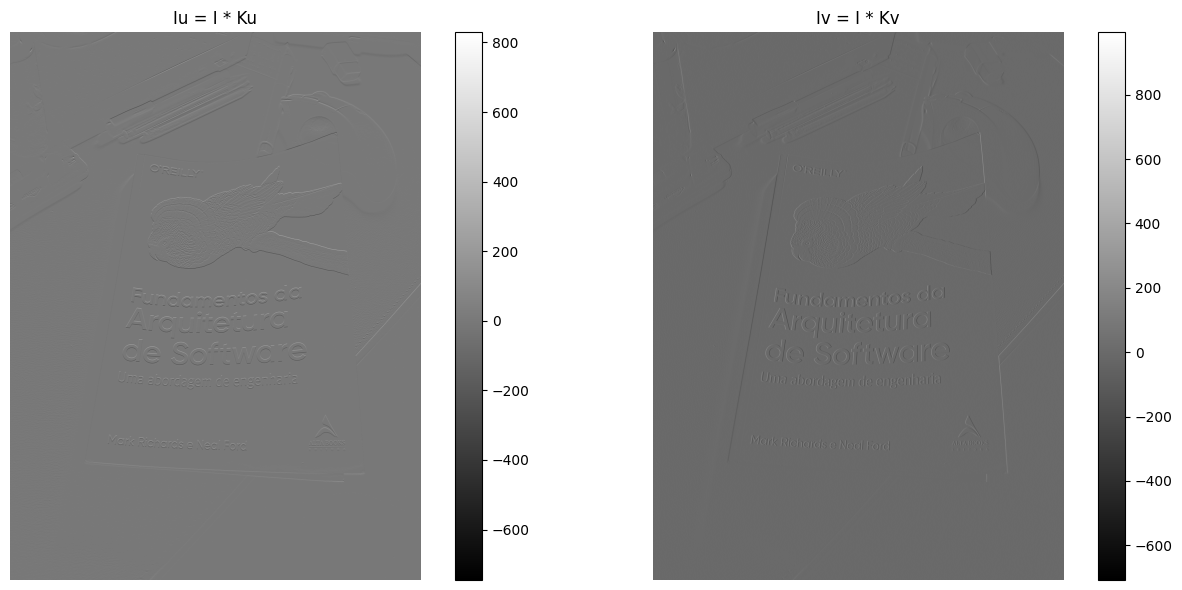

In [14]:
# Iu e Iv
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
im0 = ax[0].imshow(Iu, cmap="gray"); ax[0].set_title("Iu = I * Ku")
im1 = ax[1].imshow(Iv, cmap="gray"); ax[1].set_title("Iv = I * Kv")
for a, im in zip(ax, [im0, im1]):
    a.axis("off")
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout()
plt.show()

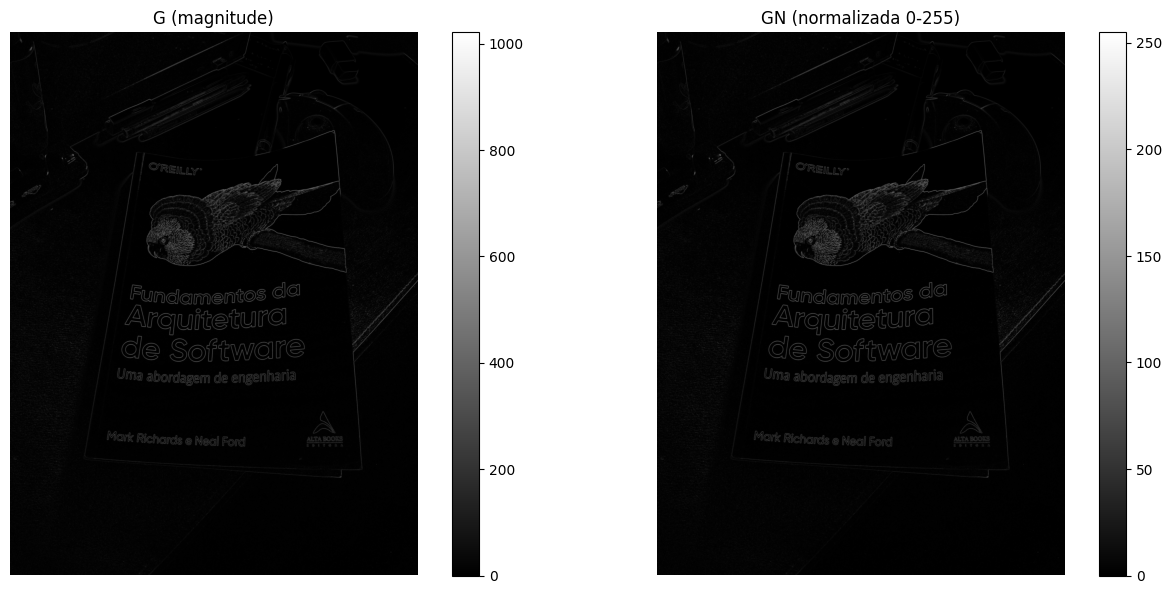

In [15]:
# magnitude do gradiente
G = np.sqrt(Iu**2 + Iv**2)
GN = cv2.normalize(G, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
im0 = ax[0].imshow(G, cmap="gray");                  ax[0].set_title("G (magnitude)")
im1 = ax[1].imshow(GN, cmap="gray", vmin=0, vmax=255); ax[1].set_title("GN (normalizada 0-255)")
for a, im in zip(ax, [im0, im1]):
    a.axis("off")
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout()
plt.show()

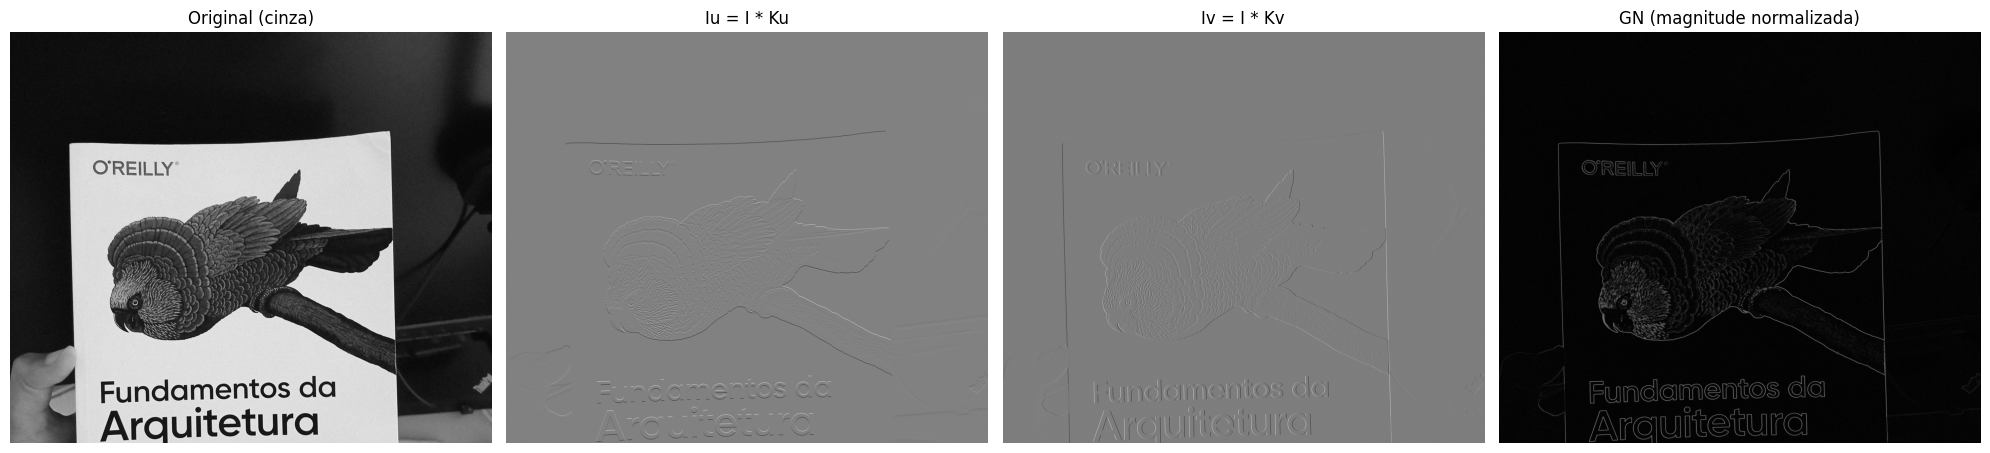

In [ ]:
# comparação das etapas
fig, ax = plt.subplots(1, 4, figsize=(20, 5))

ax[0].imshow(I, cmap="gray"); ax[0].set_title("Original (cinza)")
ax[1].imshow(Iu, cmap="gray"); ax[1].set_title("Iu = I * Ku")
ax[2].imshow(Iv, cmap="gray"); ax[2].set_title("Iv = I * Kv")
ax[3].imshow(GN, cmap="gray"); ax[3].set_title("GN (magnitude normalizada)")

for a in ax: a.axis("off")
plt.tight_layout()
plt.savefig("fig_comparação.png", dpi=100)


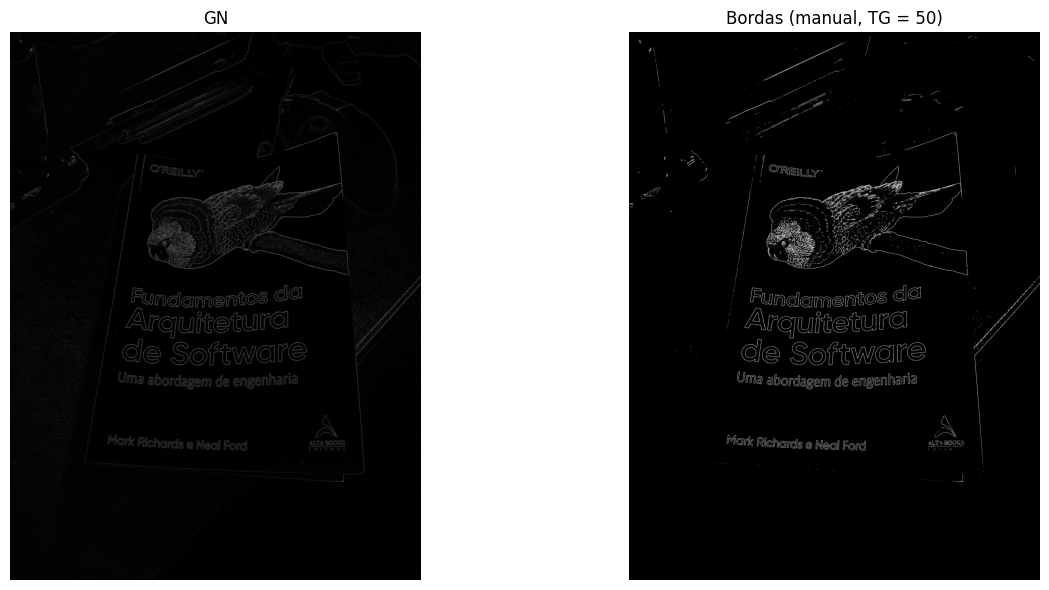

TG = 50


In [16]:
# limiar manual
TG = 50
EM = np.where(GN > TG, 255, 0).astype(np.uint8)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(GN, cmap="gray"); ax[0].set_title("GN")
ax[1].imshow(EM, cmap="gray"); ax[1].set_title(f"Bordas (manual, TG = {TG})")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()
print("TG =", TG)

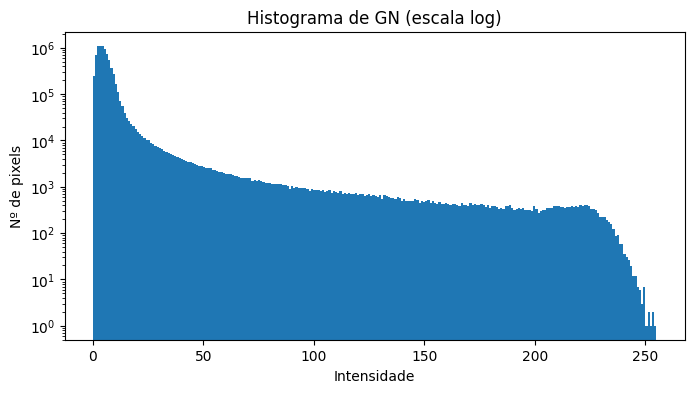

In [ ]:
# histograma de GN
plt.figure(figsize=(8, 4))
plt.hist(GN.ravel(), bins=256, log=True)
plt.title("Histograma de GN (escala log)")
plt.xlabel("Intensidade")
plt.ylabel("Nº de pixels")
plt.show()

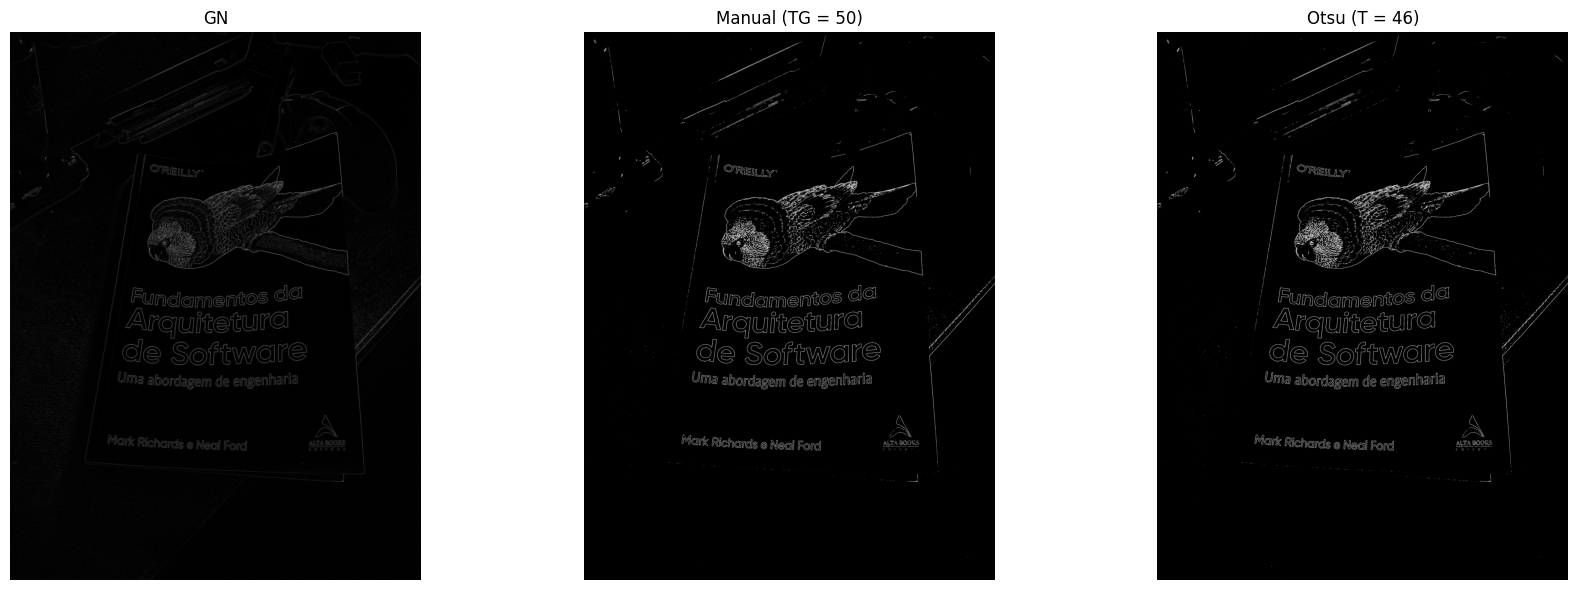

TG = 50
TOtsu = 46.0
Pixels de borda (manual): 179851
Pixels de borda (Otsu):   196316


In [17]:
TOtsu, _ = cv2.threshold(GN, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
EO = np.where(GN > TOtsu, 255, 0).astype(np.uint8)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(GN, cmap="gray"); ax[0].set_title("GN")
ax[1].imshow(EM, cmap="gray"); ax[1].set_title(f"Manual (TG = {TG})")
ax[2].imshow(EO, cmap="gray"); ax[2].set_title(f"Otsu (T = {TOtsu:.0f})")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()

print(f"TG = {TG}")
print(f"TOtsu = {TOtsu}")
print(f"Pixels de borda (manual): {np.count_nonzero(EM)}")
print(f"Pixels de borda (Otsu):   {np.count_nonzero(EO)}")